# 08-01 - Message Passing by Hand

You work the lecture's seven places by hand, from the adjacency matrix to message passing, the Laplacian and one layer of a graph convolutional network, and then train one.

First the toy and its adjacency matrix. Then message passing with sums, self-loops and averages, the Laplacian and one layer by hand. Then a small network learns the zones from three labels, and the streets become nodes. At the end you pass messages for longer.

Before you run anything, choose *File*, then *Save As*, and give the copy a name with `-mywork` in it, so that the next pull never collides with your work.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import graph_tools as gt

plt.rcParams["figure.dpi"] = 72

scene = gt.load_json("data/scene.json")
reference = gt.load_json("data/ground_truth.json")["p08"]
rules, anchors, lecture = scene["rules"], scene["anchors"], scene["lecture"]
torch_ok, pyg_ok = gt.torch_ok, gt.pyg_available()
streets, metr = lecture["streets"], lecture["metr"]
print(f"seed {scene['seed']}; {streets['n']:,} street segments, {streets['tagged']} with a speed limit")
print(f"{metr['sensors']} traffic sensors; PyTorch {'ready' if torch_ok else 'missing'}, "
      f"PyTorch Geometric {'ready' if pyg_ok else 'missing'}")

seed 20261116; 1,219 street segments, 454 with a speed limit
207 traffic sensors; PyTorch ready, PyTorch Geometric ready


## Seven places and their food

The cell loads Lecture 07's seven places with their nine edges, the places to eat at each place as the feature, and the three zones, and draws them.

7 places, 9 edges: AB, AC, BC, BD, CE, DE, DF, EG, FG
places to eat x = 0, 2, 1, 3, 1, 0, 2    lecture 0, 2, 1, 3, 1, 0, 2
zones: A W, B W, C W, D M, E M, F E, G E
labelled: A, D, G


<Axes: title={'center': 'places to eat beside each place, coloured by zone W, M, E'}>

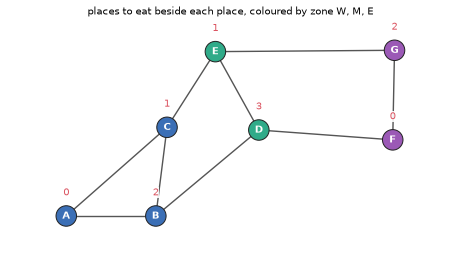

In [2]:
toy, raw, lt = gt.load_toy("data/toy.json"), gt.load_json("data/toy.json"), lecture["toy"]
nodes, x, y, zones = toy["nodes"], toy["x"], toy["y"], toy["zones"]
xy = np.array([toy["layout"][v] for v in nodes])
ZONE = np.array(["#3b6fb6", "#30AB89", "#9b59b6"])
print(f"{len(nodes)} places, {len(toy['edges'])} edges: " + ", ".join(u + v for u, v in toy["edges"]))
print("places to eat x =", ", ".join(f"{v:g}" for v in x), f"   lecture {lt['toy x']}")
print("zones:", ", ".join(f"{v} {zones[c]}" for v, c in zip(nodes, y)))
print("labelled:", ", ".join(toy["labelled"]))
fig, ax = plt.subplots(figsize=(8, 4.6))
gt.show_toy(toy["A"], xy, labels=nodes, values=x, colours=ZONE[y], ax=ax,
              title="places to eat beside each place, coloured by zone W, M, E")

The places A to G sit where Lecture 07 put them, with nine streets between them. The red number beside a place is its feature x, the places to eat there, 0, 2, 1, 3, 1, 0 and 2. The colour is the zone, the class a model will learn to predict, west for A, B and C, middle for D and E, east for F and G. Only A, D and G will be labelled.

## The adjacency matrix

The cell builds the adjacency matrix from the edge list, a one wherever two places share a street, and reads the degrees off its rows.

the same matrix as the lecture's: True
degrees 2, 3, 3, 3, 3, 2, 2    lecture 2, 3, 3, 3, 3, 2, 2
18 ones for 9 edges, the degrees sum to 18   lecture 18


<Axes: title={'center': 'A, one row and one column per place'}>

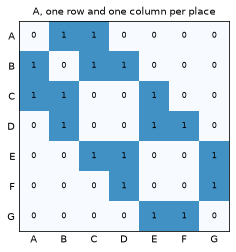

In [3]:
A = gt.adjacency(toy["edges"], nodes)
d = gt.degrees(A)
print("the same matrix as the lecture's:", bool((A == toy["A"]).all()))
print("degrees", ", ".join(f"{v:g}" for v in d), f"   lecture {lt['toy degrees']}")
print(f"{A.sum():g} ones for {len(toy['edges'])} edges, the degrees sum to {d.sum():g}"
      f"   lecture {lt['toy degree sum']}")
fig, ax = plt.subplots(figsize=(4.2, 3.8))
gt.show_matrix(A, labels=nodes, ax=ax, title="A, one row and one column per place")

Row B has ones under A, C and D, the three places B shares a street with, so the degree of B is 3. The matrix is symmetric, because a street joins its two ends both ways, so every edge appears twice and the 18 ones are twice the 9 edges. The degrees read 2, 3, 3, 3, 3, 2 and 2. The diagonal is zero, since no place is its own neighbour.

## Summing the neighbours

The cell multiplies the adjacency matrix with the feature vector and then works the row of D by hand, place by place.

In [4]:
Ax = np.dot(A, x)
print("A x =", ", ".join(f"{v:g}" for v in Ax), f"   lecture {lt['toy Ax']}")
iD = nodes.index("D")
print("row D of A:", A[iD].astype(int), "   x:", x.astype(int))
near = np.nonzero(A[iD])[0]
print("D's neighbours", ", ".join(nodes[j] for j in near))
print(" + ".join(f"{nodes[j]} {x[j]:g}" for j in near), f"= {np.dot(A[iD], x):g}")

A x = 3, 4, 3, 3, 6, 5, 1    lecture 3, 4, 3, 3, 6, 5, 1
row D of A: [0 1 0 0 1 1 0]    x: [0 2 1 3 1 0 2]
D's neighbours B, E, F
B 2 + E 1 + F 0 = 3


A product of a row with a column multiplies entry by entry and adds up. The zeros in row D drop every place D does not touch, and the ones keep B, E and F, so the sum is 2 plus 1 plus 0, which is 3. Every entry of A x is such a sum, the places to eat one street away. The whole vector reads 3, 4, 3, 3, 6, 5 and 1.

## Two rounds of message passing

The cell repeats the sum over the neighbours, each round starting from the states the last round left, and counts the places each state depends on.

           A    B    C    D    E    F    G
round 0    0    2    1    3    1    0    2   total 9
round 1    3    4    3    3    6    5    1   total 25
round 2    7    9   13   15    7    4   11   total 66
lecture round 1 3, 4, 3, 3, 6, 5, 1, round 2 7, 9, 13, 15, 7, 4, 11, total 25
places within 0 to 3 edges of A: [1, 3, 5, 7]    lecture [1, 3, 5, 7]


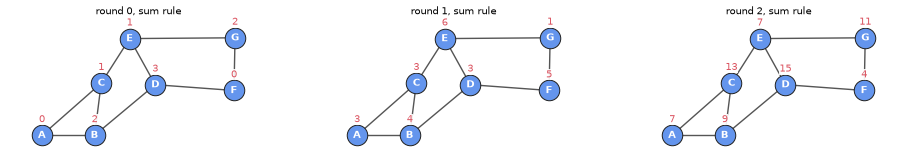

In [5]:
states = gt.message_passing(A, x, rounds=2, kind="sum")
print("        " + " ".join(f"{v:>4}" for v in nodes))
for t, s in enumerate(states):
    print(f"round {t} " + " ".join(f"{v:4g}" for v in s) + f"   total {s.sum():g}")
print(f"lecture round 1 {lt['toy sum 1']}, round 2 {lt['toy sum 2']}, total {lt['toy sum1 total']}")
reach = [int(gt.k_hop(A, 0, t).sum()) for t in range(4)]
print("places within 0 to 3 edges of A:", reach, "   lecture", raw["k_hop_from_A"][:4])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for t, ax in enumerate(axes):
    gt.show_toy(A, xy, labels=nodes, values=states[t], ax=ax, title=f"round {t}, sum rule")

Round 2 reads 7, 9, 13, 15, 7, 4 and 11. D holds 15 because it adds the round 1 values of B, E and F, 4 plus 6 plus 5. The totals grow from 9 to 25 to 66, since every value is passed to each neighbour, so a well connected place counts many times. After t rounds a state depends on every place within t edges, from A 1, 3, 5 and then all 7 places.

## Self-loops

The cell adds the identity to the adjacency matrix, so every place also hears itself, and compares one round with and without the loop.

In [6]:
loops = gt.message_passing(A, x, rounds=1, kind="sum", self_loops=True)[1]
print("            " + " ".join(f"{v:>3}" for v in nodes))
print("no loops    " + " ".join(f"{v:3g}" for v in states[1]))
print("with loops  " + " ".join(f"{v:3g}" for v in loops)
      + "   lecture " + ", ".join(lt[f"toy loops1 {v}"] for v in nodes))
print(f"D: own {x[iD]:g} + neighbours {Ax[iD]:g} = {loops[iD]:g}, without the loop {states[1][iD]:g}")
print("A + I =")
print((A + np.eye(len(nodes))).astype(int))

              A   B   C   D   E   F   G
no loops      3   4   3   3   6   5   1
with loops    3   6   4   6   7   5   3   lecture 3, 6, 4, 6, 7, 5, 3
D: own 3 + neighbours 3 = 6, without the loop 3
A + I =
[[1 1 1 0 0 0 0]
 [1 1 1 1 0 0 0]
 [1 1 1 0 1 0 0]
 [0 1 0 1 1 1 0]
 [0 0 1 1 1 0 1]
 [0 0 0 1 0 1 1]
 [0 0 0 0 1 1 1]]


Without the loop D forgets its own 3 places to eat and holds only its neighbours' 3. With the loop it holds 6. The row reads 3, 6, 4, 6, 7, 5 and 3. A place's own value is often its best clue, so every graph layer of the lecture keeps it, and the matrix it multiplies with is A plus the identity, ones on the diagonal.

## The mean and the symmetric rule

The cell divides the sums by the degrees with the loop counted, once as a plain mean and once by both ends of every edge.

mean       1.00 1.50 1.00 1.50 1.75 1.67 1.00
   lecture 1.00 1.50 1.00 1.50 1.75 1.67 1.00
symmetric  0.87 1.50 1.00 1.50 1.83 1.53 0.96
   lecture 0.87 1.50 1.00 1.50 1.83 1.53 0.96
edge D to F: 1/sqrt(4 x 3) = 1/sqrt(12) = 0.29
F = 0/3 + 3 x 0.29 + 2/3 = 1.53


<Axes: title={'center': 'symmetric rule'}>

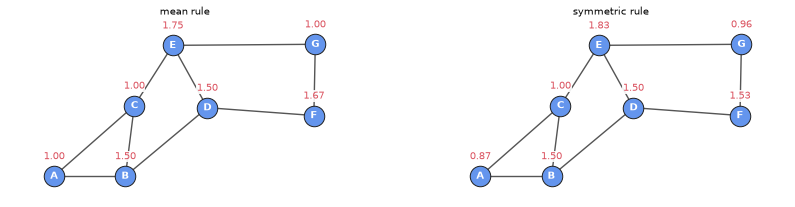

In [7]:
mean = gt.message_passing(A, x, rounds=1, kind="mean", self_loops=True)[1]
sym = gt.message_passing(A, x, rounds=1, kind="sym", self_loops=True)[1]
print("mean       " + " ".join(f"{v:.2f}" for v in mean))
print("   lecture " + " ".join(lt[f"toy mean1 {v}"] for v in nodes))
print("symmetric  " + " ".join(f"{v:.2f}" for v in sym))
print("   lecture " + " ".join(lt[f"toy sym1 {v}"] for v in nodes))
P, dt, iF = gt.normalise(A, "sym", self_loops=True), d + 1, nodes.index("F")
print(f"edge D to F: 1/sqrt({dt[iD]:g} x {dt[iF]:g}) = 1/sqrt({dt[iD] * dt[iF]:g}) = {P[iD, iF]:.2f}")
print(f"F = {x[iF]:g}/3 + {x[iD]:g} x {P[iD, iF]:.2f} + {x[6]:g}/3 = {sym[iF]:.2f}")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
gt.show_toy(A, xy, labels=nodes, values=[f"{v:.2f}" for v in mean], ax=axes[0], title="mean rule")
gt.show_toy(A, xy, labels=nodes, values=[f"{v:.2f}" for v in sym], ax=axes[1], title="symmetric rule")

The mean gives 1.00, 1.50, 1.00, 1.50, 1.75, 1.67 and 1.00, and every value stays between the smallest and the largest count. The symmetric rule divides the message from j to i by the root of both degrees. D has 4 with its loop and F has 3, so the edge weighs 1 over the root of 12, about 0.29, and F gets 1.53. A place with many neighbours shares its message out among them.

## The numbering does not matter

The cell renumbers the places twice, reversed as in the lecture and at random, passes messages in the new order and puts the result back.

In [8]:
rng = np.random.default_rng(scene["seed"])
for order in (np.arange(len(nodes))[::-1], rng.permutation(len(nodes))):
    A_new = A[np.ix_(order, order)]
    after = gt.message_passing(A_new, x[order], rounds=1, kind="sum", self_loops=True)[1]
    back = np.zeros(len(nodes))
    back[order] = after
    print("order", " ".join(nodes[k] for k in order), "  states", after.astype(int))
    print("    put back", back.astype(int))
    print("    the same as before:", bool(np.allclose(back, loops)), "   lecture:", raw["permutation_ok"])
print(f"{int(np.prod(np.arange(1, len(nodes) + 1))):,} ways to number seven places")

order G F E D C B A   states [3 5 7 6 4 6 3]
    put back [3 6 4 6 7 5 3]
    the same as before: True    lecture: True
order C G D F E B A   states [4 3 6 5 7 6 3]
    put back [3 6 4 6 7 5 3]
    the same as before: True    lecture: True
5,040 ways to number seven places


The places have no natural order, and A to G is just one of 5,040 ways to number them. Renumbering moves the rows and columns of A and the entries of x together. A sum over the neighbours does not care in which order it adds, so the states come out in the new order and, put back, are exactly 3, 6, 4, 6, 7, 5 and 3 again.

## The graph Laplacian

The cell builds the Laplacian, the degrees on the diagonal minus the adjacency matrix, compares every place with its neighbours and adds the squared differences over the edges.

L x = -3, 2, 0, 6, -3, -5, 3    lecture -3, 2, 0, 6, -3, -5, 3
D: 3 x 3 minus 3 = 6
AB 4 + AC 1 + BC 1 + BD 1 + CE 0 + DE 4 + DF 9 + EG 1 + FG 4 = 25
x'Lx = 25   lecture 25


<Axes: title={'center': 'L, the degrees minus A'}>

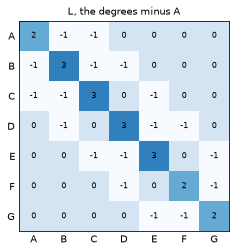

In [9]:
L = gt.laplacian(A)
Lx = np.dot(L, x)
print("L x =", ", ".join(f"{v:g}" for v in Lx), "   lecture", ", ".join(lt[f"toy Lx {v}"] for v in nodes))
print(f"D: {d[iD]:g} x {x[iD]:g} minus {Ax[iD]:g} = {Lx[iD]:g}")
squares = [(x[nodes.index(u)] - x[nodes.index(v)]) ** 2 for u, v in toy["edges"]]
print(" + ".join(f"{u}{v} {s:g}" for (u, v), s in zip(toy["edges"], squares)), f"= {sum(squares):g}")
print(f"x'Lx = {np.dot(x, Lx):g}   lecture {lt['toy smooth']}")
fig, ax = plt.subplots(figsize=(4.2, 3.8))
gt.show_matrix(L, labels=nodes, ax=ax, title="L, the degrees minus A")

Each entry of L x is a place's count times its degree minus its neighbours' counts, the sum of its differences from them. D has 3 places to eat against 2, 1 and 0 next door, so it reads 6, and F, with none against 3 and 2, reads minus 5. Then x'Lx adds the squared difference across every street, 4, 1, 1, 1, 0, 4, 9, 1 and 4, which is 25. A small number means neighbours look alike.

## The smoothest pattern on the graph

The cell computes the eigenvectors of the Laplacian and draws the second one, the Fiedler vector, the smoothest pattern that is not the same everywhere.

eigenvalues 0.00 0.75 2.20 2.45 3.55 3.80 5.25    lecture second 0.75, largest 5.25
Fiedler vector -0.53 -0.33 -0.33 0.12 0.12 0.48 0.48    lecture -0.53 -0.33 -0.33 0.12 0.12 0.48 0.48
its smoothness u'Lu = 0.75, the eigenvalue


<Axes: title={'center': 'Fiedler vector, blue below zero'}>

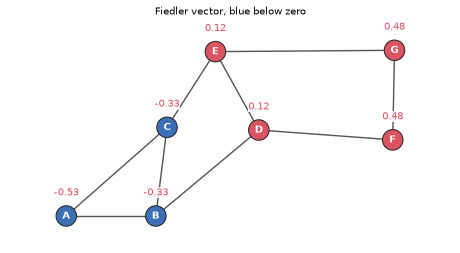

In [10]:
values, vectors = np.linalg.eigh(L)
fiedler = vectors[:, 1] * -np.sign(vectors[0, 1])
print("eigenvalues", " ".join(f"{v:.2f}" for v in np.abs(values)),
      f"   lecture second {lt['toy lambda2']}, largest {lt['toy lambda max']}")
print("Fiedler vector", " ".join(f"{v:.2f}" for v in fiedler), "   lecture",
      " ".join(lt[f"toy fiedler {v}"] for v in nodes))
print(f"its smoothness u'Lu = {np.dot(fiedler, np.dot(L, fiedler)):.2f}, the eigenvalue")
fig, ax = plt.subplots(figsize=(8, 4.6))
gt.show_toy(A, xy, labels=nodes, values=[f"{v:.2f}" for v in fiedler], ax=ax,
              colours=np.where(fiedler < 0, "#3b6fb6", "#DB5461"), title="Fiedler vector, blue below zero")

The first eigenvalue is 0, for the vector that is the same at every place. The second is 0.75, and its vector is minus 0.53 at A, minus 0.33 at B and C, 0.12 at D and E and 0.48 at F and G. It changes slowly along the streets, and its sign splits the west, A, B and C, from the rest, the one weak seam of the graph between C and E and between B and D.

## One GCN layer by hand

The cell runs one graph convolutional layer, the symmetric average with self-loops, then the lecture's weights one and minus one, then the ReLU.

W1 = [[ 1. -1.]]    one number in, two out
A hat X  0.87 1.50 1.00 1.50 1.83 1.53 0.96
 lecture 0.87 1.50 1.00 1.50 1.83 1.53 0.96
H1, first column  0.87 1.50 1.00 1.50 1.83 1.53 0.96
H1, second column 0.00 0.00 0.00 0.00 0.00 0.00 0.00
A by hand: 0/3 + (2 + 1)/sqrt(12) = 0.87, so H1 of A is (0.87, 0.00)   lecture (0.87, 0.00)


<Axes: title={'center': 'A hat, the symmetric average with self-loops'}>

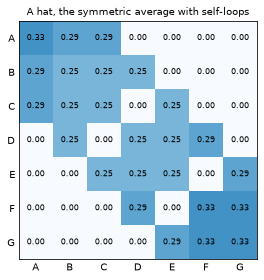

In [11]:
W1, X = np.array(raw["W1"]), x[:, None]
PX = np.dot(P, X)
H1 = gt.gcn_layer(A, X, W1)
print("W1 =", W1, "   one number in, two out")
print("A hat X  " + " ".join(f"{v:.2f}" for v in PX[:, 0]))
print(" lecture " + " ".join(lt[f"toy PX {v}"] for v in nodes))
print("H1, first column  " + " ".join(f"{v:.2f}" for v in H1[:, 0]))
print("H1, second column " + " ".join(f"{v:.2f}" for v in H1[:, 1]))
print(f"A by hand: 0/3 + (2 + 1)/sqrt(12) = {3 / np.sqrt(12):.2f}, so H1 of A is "
      f"({H1[0, 0]:.2f}, {H1[0, 1]:.2f})   lecture ({lt['toy H1a A']}, {lt['toy H1b A']})")
fig, ax = plt.subplots(figsize=(4.8, 4.3))
gt.show_matrix(P, labels=nodes, ax=ax, fmt="{:.2f}", title="A hat, the symmetric average with self-loops")

The matrix A hat holds only three different weights, one third between two places of degree 2, 0.29 between a place of degree 2 and one of degree 3, and one quarter between two of degree 3. Its product with x is the symmetric rule again. The weights 1 and minus 1 copy that column and its negative, and the ReLU sets the negative column to zero, so A leaves the layer as (0.87, 0.00).

## The loss before any learning

The cell gives the layer weights of zero for three zones, so every place gets one third per zone, and scores that with the cross-entropy on the three labelled places.

In [12]:
labelled = np.array([nodes.index(v) for v in toy["labelled"]])
rest = np.setdiff1d(np.arange(len(nodes)), labelled)
start = gt.gcn_layer(A, X, np.zeros((1, 3)), activation="softmax")
print("probabilities of zones W, M, E at A:", np.round(start[0], 3))
print(f"loss on A, D and G: {gt.cross_entropy(start, y, labelled):.2f}, ln 3 = {np.log(3):.2f}"
      f"   lecture {lt['toy loss uniform']}")
sure = np.eye(3)[y] * 0.97 + 0.01
print(f"a model 98 percent sure of the right zone: {gt.cross_entropy(sure, y, labelled):.2f}")

probabilities of zones W, M, E at A: [0.333 0.333 0.333]
loss on A, D and G: 1.10, ln 3 = 1.10   lecture 1.10
a model 98 percent sure of the right zone: 0.02


A model that knows nothing gives each zone one third, and the cross-entropy is minus the logarithm of the probability of the true zone, averaged over A, D and G. That is ln 3, 1.10, the number a training curve with three classes starts from. A model 98 percent sure of every right zone costs 0.02. Training pushes the loss from the first number towards the second.

## Training on three labels

The cell trains the lecture's two-layer GCN, four hidden numbers and only each place's name as its feature, on A, D and G, and the same network without the graph.

GCN      W W W M M E E   4 of 4 right, lecture W W W M M E E
no graph W M M M M M E   1 of 4 right, lecture W M M M M M E
47 weights, loss at epoch 1 1.105   lecture 47, 1.105


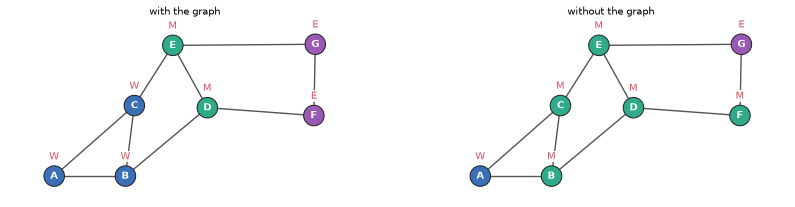

In [13]:
ref, settings = raw["gcn"]["one_hot"], dict(epochs=200, lr=0.05, weight_decay=0.0, seed=gt.SEED)
if torch_ok:
    h = gt.fit(gt.GCN(7, 4, 3, dropout=0.0), gt.one_hot(7), P, y, labelled, labelled, **settings)
    hm = gt.fit(gt.MLP(7, 4, 3, dropout=0.0), gt.one_hot(7), None, y, labelled, labelled, **settings)
    for name, run, lec in (("GCN", h, ref["pred"]), ("no graph", hm, ref["mlp_pred"])):
        right = int((run["pred"][rest] == y[rest]).sum())
        print(f"{name:8s}", *[zones[k] for k in run["pred"]], f"  {right} of 4 right, lecture", *lec)
    print(f"{gt.count_parameters(gt.GCN(7, 4, 3))} weights, loss at epoch 1 {h['train_loss'][0]:.3f}"
          f"   lecture {lt['toy gcn onehot params']}, {ref['loss_first']:.3f}")
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
    for ax, (title, run) in zip(axes, (("with the graph", h), ("without the graph", hm))):
        gt.show_toy(A, xy, labels=nodes, values=[zones[k] for k in run["pred"]], colours=ZONE[run["pred"]],
                      ax=ax, title=title)
else:
    print(gt.NO_TORCH)

Read the two rows against the lecture's. In the lecture the GCN named all four unlabelled places right, B and C west, E middle, F east, and the network without the graph got one of four, calling almost everything middle. A name tells nothing about an unseen place, so the answer came from the graph alone. The loss at the first epoch sits near ln 3, as the last section predicted.

## Streets as nodes

The cell turns the toy's nine streets into the nodes of a new graph, the line graph, two of them joined where they meet at a place.

9 streets as nodes, 15 pairs that meet, degrees [3 3 4 4 4 4 3 3 2]
  AB meets AC, BC, BD
  AC meets AB, BC, CE
  BC meets AB, AC, BD, CE
  BD meets AB, BC, DE, DF
  CE meets AC, BC, DE, EG
  DE meets BD, CE, DF, EG
  DF meets BD, DE, FG
  EG meets CE, DE, FG
  FG meets DF, EG


<Axes: title={'center': 'its line graph, streets as nodes'}>

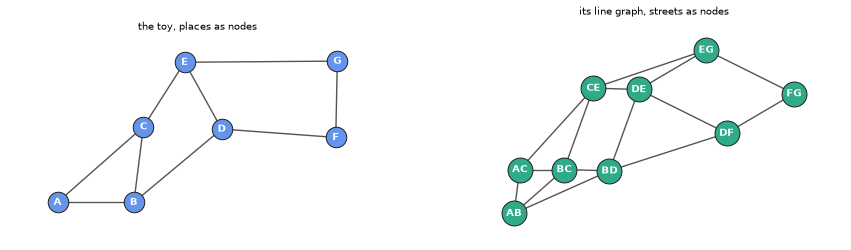

In [14]:
LG = gt.line_graph(toy["edges"])
names = [u + v for u, v in toy["edges"]]
mid = np.array([(xy[nodes.index(u)] + xy[nodes.index(v)]) / 2 for u, v in toy["edges"]])
print(f"{len(names)} streets as nodes, {LG.sum() / 2:g} pairs that meet, degrees", gt.degrees(LG).astype(int))
for k, s in enumerate(names):
    print(f"  {s} meets " + ", ".join(names[j] for j in np.nonzero(LG[k])[0]))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
gt.show_graph(A, xy, labels=nodes, ax=axes[0], title="the toy, places as nodes")
gt.show_graph(LG, mid, labels=names, ax=axes[1], size=620, colours="#30AB89",
              title="its line graph, streets as nodes")

Each street becomes a node at its midpoint, and two streets are joined when they share a place. AB meets AC at A and BC and BD at B, while FG meets only DF and EG. The nine nodes are joined by 15 edges. A speed limit belongs to a street, not to a crossing, so a model that predicts it needs the streets as its nodes.

## Your turn

The mean rule with self-loops ran for one and two rounds above. Run it for many more and watch the gap between the place with the highest state and the place with the lowest. Run the cell as it is, then change the marked value and run it again.

What happens to the differences between the places, and what does that mean for a network with many layers? Write your answer in one or two sentences. The answer comes in Friday's post, not in the kit.

after 2 rounds: 1.17 1.25 1.31 1.60 1.31 1.39 1.47
highest minus lowest 0.4375, at the start 3
mean squared difference across the edges 0.035714


<Axes: title={'center': 'round 2, mean rule'}>

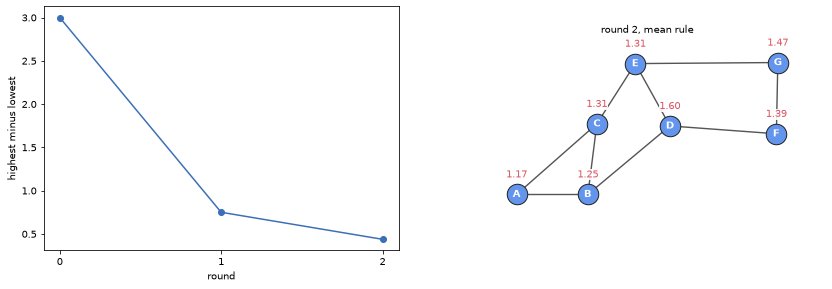

In [15]:
ROUNDS = 2  # change me: 32
smooth = gt.message_passing(A, x, rounds=ROUNDS, kind="mean", self_loops=True)
last = smooth[-1]
print(f"after {ROUNDS} rounds: " + " ".join(f"{v:.2f}" for v in last))
print(f"highest minus lowest {last.max() - last.min():.4f}, at the start {x.max() - x.min():g}")
print(f"mean squared difference across the edges {gt.dirichlet_energy(A, last[:, None]):.6f}")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
axes[0].plot([s.max() - s.min() for s in smooth], "o-", color="#3b6fb6")
axes[0].set_xlabel("round")
axes[0].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].set_ylabel("highest minus lowest")
gt.show_toy(A, xy, labels=nodes, values=[f"{v:.2f}" for v in last], ax=axes[1],
              title=f"round {ROUNDS}, mean rule")

## Check your understanding

1. Explain D's 15 after two rounds of the sum rule from the first round's values of B, E and F.
2. What does a place forget without a self-loop, and when does that matter?
3. Under the symmetric rule, why does a message from a place with many neighbours count less?
4. The GCN learned the zones from one-hot features, the model without the graph did not. Where did its answer come from, and why could it not name an eighth place added later?

## Where we are

You have built the adjacency matrix of seven places, passed messages with sums, self-loops and two kinds of average, checked that the numbering changes nothing, measured smoothness with the Laplacian, run one GCN layer by hand and trained a small one on three labels. In 08-02 the nodes are Princeton's 1,219 street segments, joined where they meet, and the same two layers learn the speed limits the map does not know.

## Further resources

Nothing in this course requires anything below.

- Graph Representation Learning, William L. Hamilton, Morgan and Claypool 2020, chapter 5, The Graph Neural Network Model, pages 48 to 54 on message passing and its normalisations, the pre-publication version free at https://www.cs.mcgill.ca/~wlh/grl_book/
- Semi-Supervised Classification with Graph Convolutional Networks, Thomas N. Kipf and Max Welling, ICLR 2017, https://arxiv.org/abs/1609.02907
- A Gentle Introduction to Graph Neural Networks, Benjamin Sanchez-Lengeling, Emily Reif, Adam Pearce and Alexander B. Wiltschko, Distill 2021, https://distill.pub/2021/gnn-intro/

The tables, numbers and this kit are the course's own work, published under CC BY 4.0.